 MODEL ARTEFACT LIFECYCLE EXPERIMENT

[1] Installing required libraries...
Execution device: cpu

[2] Creating CNN architecture...
CNNModel(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total parameters: 206922


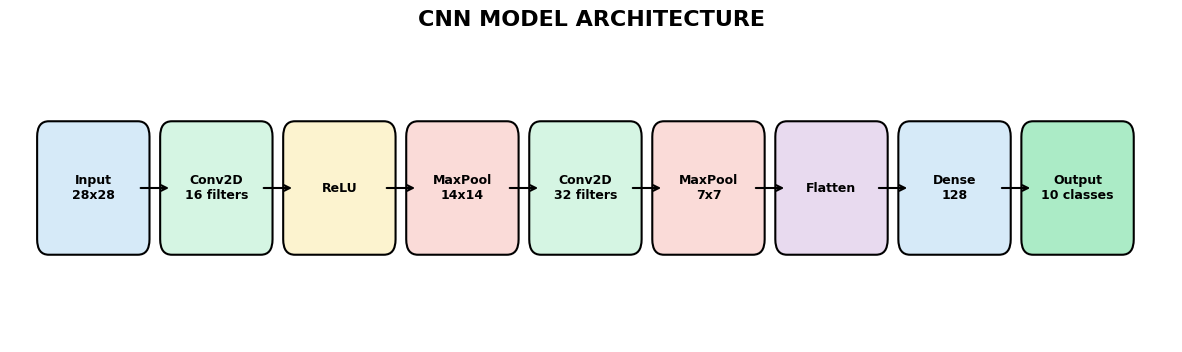


[3] Loading MNIST dataset...


100%|██████████| 9.91M/9.91M [00:00<00:00, 15.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 397kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.77MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.63MB/s]



[4] Training CNN model...
Epoch 1/2 | Loss: 0.3172 | Accuracy: 90.92% | Time: 34.7s
Epoch 2/2 | Loss: 0.0783 | Accuracy: 97.60% | Time: 41.5s

[5] Evaluating trained model...
Test Accuracy: 98.34%

[6] Saving trained checkpoint...
Saved: model_checkpoint.pth

[7] Exporting model into ONNX format...
Saved: model.onnx

[8] Validating ONNX graph...
ONNX graph validation: SUCCESS
Number of ONNX nodes: 10

ONNX operations:
  Conv
  Relu
  MaxPool
  Conv
  Relu
  MaxPool
  Flatten
  Gemm
  Relu
  Gemm

[9] Testing ONNX model...


/tmp/ipykernel_1093/2305251733.py:243: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Actual labels:     [7 2 1 0 4 1 4 9]
Predicted labels:  [7 2 1 0 4 1 4 9]

[10] Checking TensorRT availability...
TensorRT engine generation skipped.
Reason: trtexec or CUDA-enabled GPU is unavailable.
ONNX model is ready for TensorRT conversion.

[11] Displaying model lifecycle...


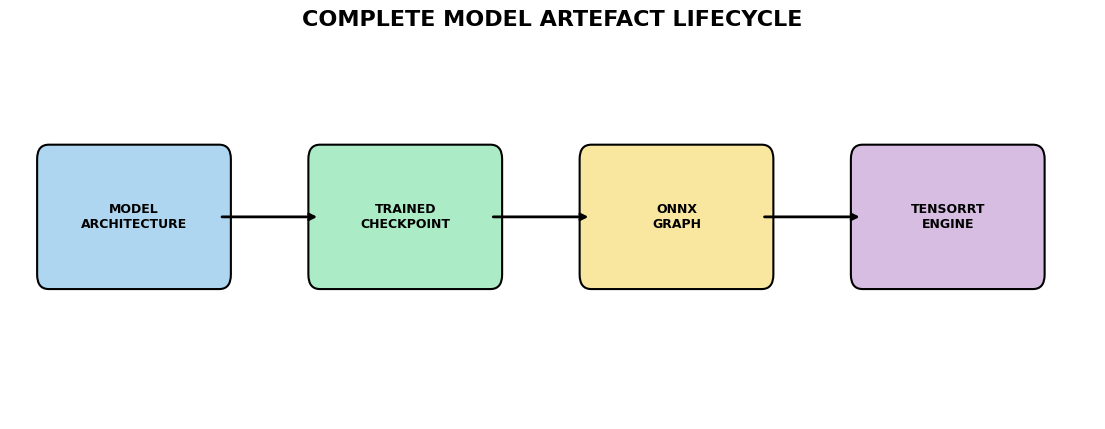


[12] Visualizing digit predictions...


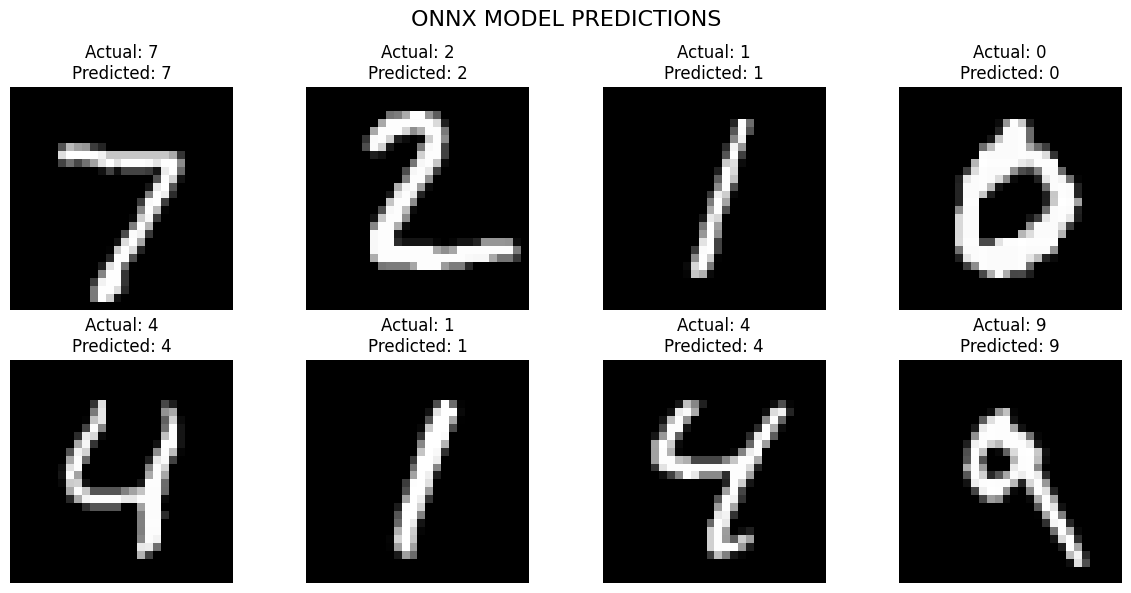


[13] GENERATED MODEL ARTEFACTS
SUCCESS: model_checkpoint.pth (2.38 MB)
SUCCESS: model.onnx (0.79 MB)
NOT GENERATED: model.engine

 EXPERIMENT COMPLETED
Training Accuracy: 97.6 %
Testing Accuracy: 98.34 %
ONNX Validation: SUCCESS
TensorRT Engine: SKIPPED


In [1]:

# ============================================================
# DEEP LEARNING EXPERIMENT
# MODEL ARTEFACT LIFECYCLE
# Architecture -> Checkpoint -> ONNX -> TensorRT
# ============================================================

import os
import sys
import time
import subprocess
import importlib.util
import shutil
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Image

print("=" * 65)
print(" MODEL ARTEFACT LIFECYCLE EXPERIMENT")
print("=" * 65)

# 1. INSTALL REQUIRED LIBRARIES
print("\n[1] Installing required libraries...")

subprocess.run([
    sys.executable, "-m", "pip", "install", "-q",
    "onnx", "onnxruntime"
], check=True)

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import onnx
import onnxruntime as ort

from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Execution device:", device)

# 2. DEFINE MODEL ARCHITECTURE
print("\n[2] Creating CNN architecture...")

class CNNModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = CNNModel().to(device)

print(model)
print("\nTotal parameters:",
      sum(p.numel() for p in model.parameters()))

# 3. VISUALIZE ARCHITECTURE
def draw_box(ax, x, y, width, height, title, color):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.15",
        facecolor=color,
        edgecolor="black",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(x + width/2, y + height/2,
            title, ha="center", va="center",
            fontsize=9, weight="bold")

fig, ax = plt.subplots(figsize=(15, 4))
ax.set_xlim(0, 15)
ax.set_ylim(0, 3)
ax.axis("off")

layers = [
    ("Input\n28x28", "#D6EAF8"),
    ("Conv2D\n16 filters", "#D5F5E3"),
    ("ReLU", "#FCF3CF"),
    ("MaxPool\n14x14", "#FADBD8"),
    ("Conv2D\n32 filters", "#D5F5E3"),
    ("MaxPool\n7x7", "#FADBD8"),
    ("Flatten", "#E8DAEF"),
    ("Dense\n128", "#D6EAF8"),
    ("Output\n10 classes", "#ABEBC6")
]

positions = np.linspace(0.5, 13.2, len(layers))

for i, (name, color) in enumerate(layers):
    draw_box(ax, positions[i], 1, 1.15, 1, name, color)

    if i < len(layers)-1:
        ax.annotate(
            "", xy=(positions[i+1], 1.5),
            xytext=(positions[i]+1.15, 1.5),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

ax.set_title("CNN MODEL ARCHITECTURE", fontsize=16, weight="bold")
plt.show()

# 4. LOAD MNIST DATASET
print("\n[3] Loading MNIST dataset...")

transform = transforms.ToTensor()

train_data = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_data, batch_size=128, shuffle=True
)

test_loader = DataLoader(
    test_data, batch_size=256, shuffle=False
)

# 5. TRAIN MODEL
print("\n[4] Training CNN model...")

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 2
training_accuracy = []

for epoch in range(epochs):

    model.train()
    correct = 0
    total = 0
    running_loss = 0

    start = time.time()

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    accuracy = 100 * correct / total
    training_accuracy.append(accuracy)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {running_loss/len(train_loader):.4f} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Time: {time.time()-start:.1f}s"
    )

# 6. EVALUATE MODEL
print("\n[5] Evaluating trained model...")

model.eval()
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

# 7. SAVE TRAINED CHECKPOINT
print("\n[6] Saving trained checkpoint...")

checkpoint = {
    "epoch": epochs,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "accuracy": test_accuracy
}

torch.save(checkpoint, "model_checkpoint.pth")

print("Saved: model_checkpoint.pth")

# 8. EXPORT MODEL TO ONNX
print("\n[7] Exporting model into ONNX format...")

model.eval()

dummy_input = torch.randn(1, 1, 28, 28).to(device)

torch.onnx.export(
    model,
    dummy_input,
    "model.onnx",
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "output": {0: "batch_size"}
    },
    opset_version=17,
    dynamo=False
)

print("Saved: model.onnx")

# 9. VALIDATE ONNX GRAPH
print("\n[8] Validating ONNX graph...")

onnx_model = onnx.load("model.onnx")
onnx.checker.check_model(onnx_model)

print("ONNX graph validation: SUCCESS")
print("Number of ONNX nodes:", len(onnx_model.graph.node))

print("\nONNX operations:")
for node in onnx_model.graph.node:
    print(" ", node.op_type)

# 10. RUN ONNX RUNTIME INFERENCE
print("\n[9] Testing ONNX model...")

session = ort.InferenceSession(
    "model.onnx",
    providers=["CPUExecutionProvider"]
)

sample_images, sample_labels = next(iter(test_loader))

onnx_input = sample_images[:8].numpy()

onnx_outputs = session.run(
    ["output"],
    {"input": onnx_input}
)[0]

onnx_predictions = np.argmax(onnx_outputs, axis=1)

print("Actual labels:    ", sample_labels[:8].numpy())
print("Predicted labels: ", onnx_predictions)

# 11. TENSORRT ENGINE GENERATION
print("\n[10] Checking TensorRT availability...")

engine_created = False

trtexec = shutil.which("trtexec")

if trtexec and torch.cuda.is_available():

    print("TensorRT trtexec detected.")

    command = [
        trtexec,
        "--onnx=model.onnx",
        "--saveEngine=model.engine",
        "--fp16",
        "--skipInference"
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    if result.returncode == 0 and os.path.exists("model.engine"):
        print("TensorRT engine generated successfully!")
        engine_created = True
    else:
        print("TensorRT engine generation failed.")
        print(result.stderr[-1500:])

else:
    print("TensorRT engine generation skipped.")
    print("Reason: trtexec or CUDA-enabled GPU is unavailable.")
    print("ONNX model is ready for TensorRT conversion.")

# 12. VISUALIZE MODEL ARTEFACT LIFECYCLE
print("\n[11] Displaying model lifecycle...")

fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 4)
ax.axis("off")

steps = [
    ("MODEL\nARCHITECTURE", "#AED6F1"),
    ("TRAINED\nCHECKPOINT", "#ABEBC6"),
    ("ONNX\nGRAPH", "#F9E79F"),
    ("TENSORRT\nENGINE", "#D7BDE2")
]

x_positions = [0.5, 4, 7.5, 11]

for i, (name, color) in enumerate(steps):

    draw_box(ax, x_positions[i], 1.5, 2.2, 1.2, name, color)

    if i < 3:
        ax.annotate(
            "", xy=(x_positions[i+1], 2.1),
            xytext=(x_positions[i]+2.2, 2.1),
            arrowprops=dict(arrowstyle="->", lw=2)
        )

ax.set_title(
    "COMPLETE MODEL ARTEFACT LIFECYCLE",
    fontsize=16, weight="bold"
)

plt.show()

# 13. DISPLAY PREDICTION IMAGES
print("\n[12] Visualizing digit predictions...")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    ax.imshow(onnx_input[i][0], cmap="gray")

    ax.set_title(
        f"Actual: {sample_labels[i].item()}\n"
        f"Predicted: {onnx_predictions[i]}"
    )

    ax.axis("off")

plt.suptitle("ONNX MODEL PREDICTIONS", fontsize=16)
plt.tight_layout()
plt.show()

# 14. DISPLAY GENERATED ARTEFACTS
print("\n[13] GENERATED MODEL ARTEFACTS")

files = [
    "model_checkpoint.pth",
    "model.onnx",
    "model.engine"
]

for file in files:

    if os.path.exists(file):
        size = os.path.getsize(file) / (1024 * 1024)
        print(f"SUCCESS: {file} ({size:.2f} MB)")
    else:
        print(f"NOT GENERATED: {file}")

print("\n" + "=" * 65)
print(" EXPERIMENT COMPLETED")
print("=" * 65)
print("Training Accuracy:", round(training_accuracy[-1], 2), "%")
print("Testing Accuracy:", round(test_accuracy, 2), "%")
print("ONNX Validation: SUCCESS")
print("TensorRT Engine:", "CREATED" if engine_created else "SKIPPED")
print("=" * 65)
